Project Description

This project aims to predict house prices using the California Housing dataset and the Linear Regression algorithm. The dataset was preprocessed by handling missing values and encoding categorical features. The data was then divided into training and testing sets. A Linear Regression model was trained to predict house prices based on various housing features. Finally, the model was evaluated using performance metrics such as MAE, MSE, RMSE, and R² Score, and the predicted values were compared with the actual values.

In [ ]:
import pandas as pd

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving housing (1).txt to housing (1) (1).txt


In [ ]:
df = pd.read_csv("housing (1).txt")

In [ ]:
import os
print(os.listdir())

['.config', 'housing (1).txt', 'housing (1) (1).txt', 'sample_data']


In [ ]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
df = df.dropna()

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["ocean_proximity"] = le.fit_transform(df["ocean_proximity"])

In [ ]:
print(df.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')


In [ ]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

print(X.shape)
print(y.shape)

(20433, 9)
(20433,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 51388.700189508156
MSE: 4924108937.912002
RMSE: 70171.99539639728
R2 Score: 0.6399236679243365


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,245800.0,195854.433791
1,137900.0,157564.349841
2,218200.0,202476.830299
3,220800.0,173038.268113
4,170500.0,214022.310405
5,75000.0,108153.487292
6,269400.0,285498.593116
7,228900.0,249462.774553
8,500001.0,390860.391419
9,80800.0,49344.176325


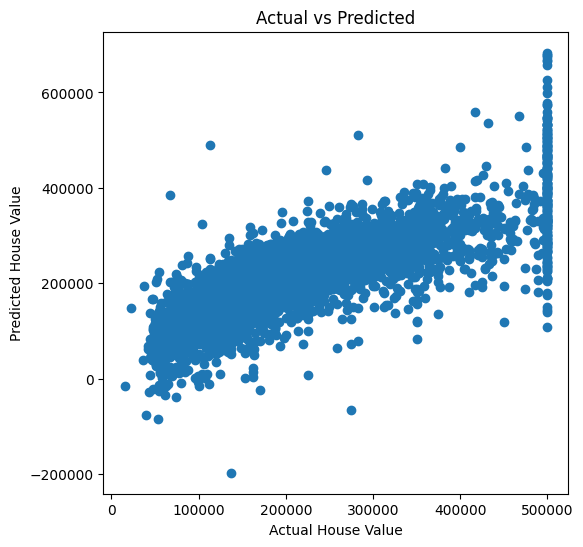

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted")
plt.show()

In [ ]:
sample = X.iloc[[0]]
prediction = model.predict(sample)
print("Predicted House Value:", prediction[0])

Predicted House Value: 410287.17646527383


In [ ]:
results.to_csv("housing_predictions.csv", index=False)
print("File saved successfully")

File saved successfully


In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

feature_importance

,Feature,Coefficient
0,longitude,-42768.679958
1,latitude,-42483.039762
2,housing_median_age,1156.796736
3,total_rooms,-8.373636
4,total_bedrooms,115.960836
5,population,-36.876653
6,households,41.465907
7,median_income,40259.549444
8,ocean_proximity,-394.098726


Conclusion

The House Price Prediction project was successfully completed using the Linear Regression algorithm. The dataset was cleaned, preprocessed, and used to train the model. The model generated accurate predictions and was evaluated using standard regression metrics. This project demonstrates the effectiveness of machine learning in predicting house prices and highlights the importance of data preprocessing and model evaluation for achieving reliable results.